<a href="https://colab.research.google.com/github/Veniveni123/CSA47-DEEP-LEARNING/blob/main/LAB%2021-30/Experiment%2029%3A%20VAE/GAN%20Sample%20Generation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

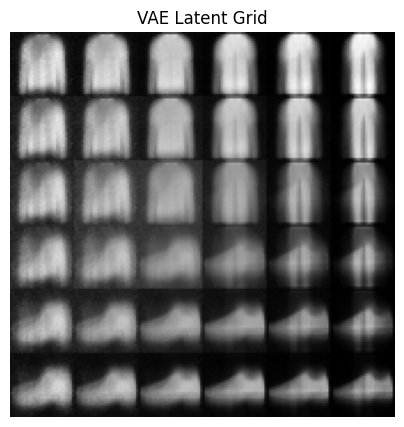

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


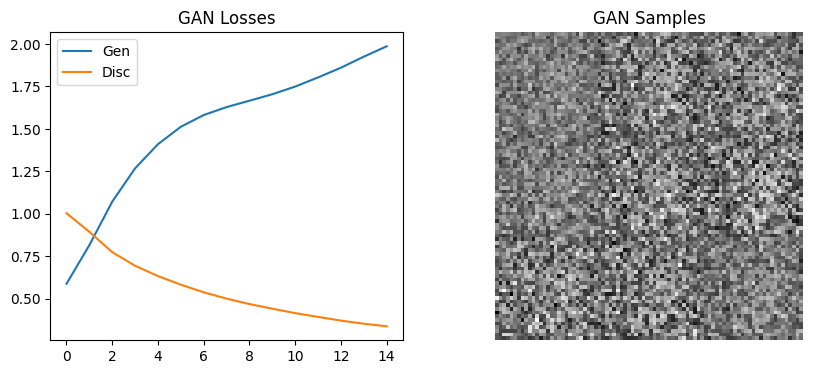

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

np.random.seed(42)
tf.random.set_seed(42)

(X_tr, _), _ = keras.datasets.fashion_mnist.load_data()
X_train = X_tr[:2000].astype('float32') / 255.0
X_flat = X_train.reshape(-1, 784)

enc_in = keras.Input(shape=(784,))
h = keras.layers.Dense(64, activation='relu')(enc_in)
zm = keras.layers.Dense(2)(h)
zlv = keras.layers.Dense(2)(h)
z = keras.layers.Lambda(lambda a: a[0] + tf.exp(0.5 * a[1]) * tf.random.normal(tf.shape(a[0])))([zm, zlv])
enc = keras.Model(enc_in, [zm, zlv, z])

dec_in = keras.Input(shape=(2,))
dec = keras.Model(dec_in, keras.layers.Dense(784, activation='sigmoid')(keras.layers.Dense(64, activation='relu')(dec_in)))

class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder

    def train_step(self, d):
        with tf.GradientTape() as tape:
            m, lv, zs = self.encoder(d)
            r = self.decoder(zs)
            loss = tf.reduce_mean(tf.reduce_sum(keras.losses.binary_crossentropy(d, r), -1) - 0.5 * tf.reduce_sum(1 + lv - m**2 - tf.exp(lv), -1))
        self.optimizer.apply_gradients(zip(tape.gradient(loss, self.trainable_weights), self.trainable_weights))
        return {"loss": loss}

vae = VAE(enc, dec)
vae.compile(optimizer='adam')
vae.fit(X_flat, epochs=6, batch_size=64, verbose=0)

grid = np.linspace(-2, 2, 6)
canvas = np.zeros((28*6, 28*6))
for i, yi in enumerate(grid):
    for j, xi in enumerate(grid):
        canvas[i*28:(i+1)*28, j*28:(j+1)*28] = dec.predict(np.array([[xi, yi]]), verbose=0)[0].reshape(28, 28)

plt.figure(figsize=(5, 5))
plt.imshow(canvas, cmap='gray'); plt.title("VAE Latent Grid"); plt.axis('off')
plt.show()

gen = keras.Sequential([keras.layers.Dense(64, activation='relu', input_shape=(16,)), keras.layers.Dense(784, activation='sigmoid'), keras.layers.Reshape((28, 28))])
disc = keras.Sequential([keras.layers.Flatten(input_shape=(28, 28)), keras.layers.Dense(64, activation='relu'), keras.layers.Dense(1, activation='sigmoid')])
disc.compile(optimizer='adam', loss='binary_crossentropy')
disc.trainable = False
gan_in = keras.Input(shape=(16,))
gan = keras.Model(gan_in, disc(gen(gan_in)))
gan.compile(optimizer='adam', loss='binary_crossentropy')

gl, dl = [], []
for _ in range(15):
    real = X_train[np.random.randint(0, len(X_train), 64)]
    fake = gen.predict(np.random.randn(64, 16), verbose=0)
    disc.trainable = True
    dl.append(0.5 * (disc.train_on_batch(real, np.ones((64, 1))) + disc.train_on_batch(fake, np.zeros((64, 1)))))
    disc.trainable = False
    gl.append(gan.train_on_batch(np.random.randn(64, 16), np.ones((64, 1))))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(gl, label='Gen'); axes[0].plot(dl, label='Disc'); axes[0].set_title("GAN Losses"); axes[0].legend()
s = gen.predict(np.random.randn(9, 16), verbose=0)
axes[1].imshow(np.block([[s[i*3+j] for j in range(3)] for i in range(3)]), cmap='gray'); axes[1].set_title("GAN Samples"); axes[1].axis('off')
plt.show()